Loading MNIST dataset...
Applying t-SNE (this may take a few minutes)...


c:\Users\TGawade\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\manifold\_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


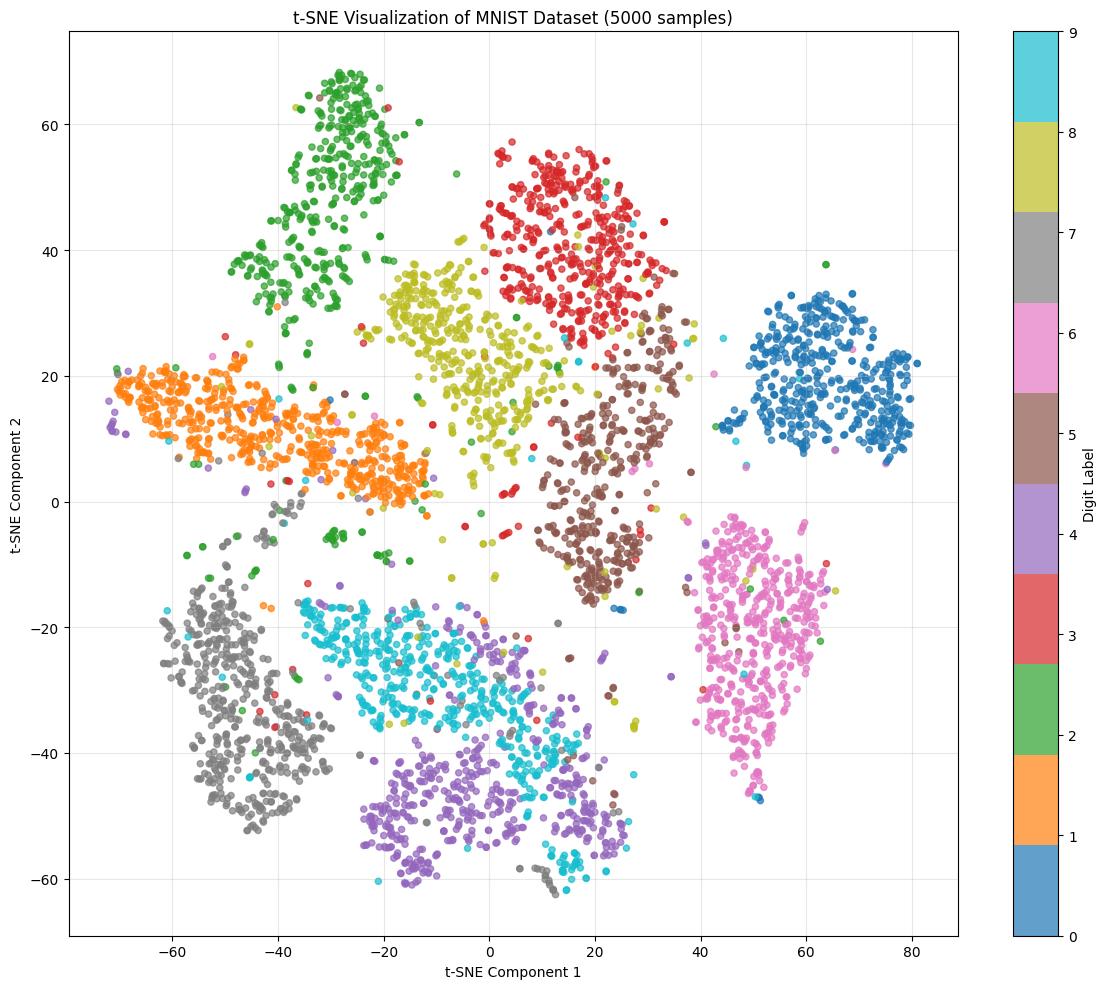

t-SNE visualization complete!


In [2]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml
import numpy as np

# Load the MNIST dataset (70,000 samples of 28x28 images)
# Each image is flattened from 28x28 pixels to a 784-dimensional vector
print("Loading MNIST dataset...")
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
# mnist_784 is the dataset name where '784' refers to 28*28 = 784 features

X = mnist.data                      # Feature matrix: shape (70000, 784)
                                    # Each row represents one handwritten digit image
                                    
y = mnist.target.astype(int)        # Labels: shape (70000,)
                                    # Convert labels from string to integer (0-9)

# Use a subset for faster computation (t-SNE is computationally expensive)
# t-SNE has O(n²) complexity, so we use fewer samples
n_samples = 5000                    # Number of samples to use (out of 70,000)

X_subset = X[:n_samples]            # Take first 5000 images
                                    # Shape: (5000, 784)
                                    
y_subset = y[:n_samples]            # Take first 5000 labels
                                    # Shape: (5000,)

# Apply t-SNE to reduce to 2D
# t-SNE converts high-dimensional data to low-dimensional while preserving local structure
print("Applying t-SNE (this may take a few minutes)...")

tsne = TSNE(
    n_components=2,                 # Reduce to 2 dimensions for visualization
    random_state=42,                # Set seed for reproducibility
    perplexity=30,                  # Balance between local and global structure (typical: 5-50)
    n_iter=1000                     # Number of optimization iterations
)

X_tsne = tsne.fit_transform(X_subset)  
# Apply t-SNE transformation
# Input: (5000, 784) → Output: (5000, 2)
# Each 784-dimensional point is now mapped to 2D

# Visualize the t-SNE results
plt.figure(figsize=(12, 10))        # Create figure with size 12x10 inches

scatter = plt.scatter(
    X_tsne[:, 0],                   # X-axis: first t-SNE component
    X_tsne[:, 1],                   # Y-axis: second t-SNE component
    c=y_subset,                     # Color points by their digit label (0-9)
    cmap='tab10',                   # Use 'tab10' colormap (10 distinct colors)
    alpha=0.7,                      # Set transparency to 0.7 (70% opaque)
    s=20                            # Set point size to 20
)

plt.xlabel('t-SNE Component 1')     # Label for x-axis
plt.ylabel('t-SNE Component 2')     # Label for y-axis

plt.title(f't-SNE Visualization of MNIST Dataset ({n_samples} samples)')
# Title showing method and number of samples

plt.colorbar(scatter, label='Digit Label')  
# Add colorbar showing which color represents which digit (0-9)

plt.grid(True, alpha=0.3)           # Add grid with 30% transparency
plt.tight_layout()                  # Adjust layout to prevent label cutoff
plt.show()                          # Display the plot

print("t-SNE visualization complete!")